In [1]:
from datasets import load_dataset
dataset = load_dataset("amitkedia/Financial-Fraud-Dataset", split="train")
print(dataset)


C:\Users\Dell\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset({
    features: ['Fillings', 'Fraud'],
    num_rows: 170
})


In [2]:
import pandas as pd

df = pd.DataFrame(dataset)
df.head()


,Fillings,Fraud
0,nanitem 14 exhibits financial statements repor...,yes
1,item 14 principal accounting fees services mat...,no
2,item 14 exhibits financial statements schedule...,yes
3,item 14 exhibits financial statement schedules...,yes
4,item 14 exhibits financial statement schedules...,no


In [3]:
print(df.columns)
print(df.info())
print(df.describe())


Index(['Fillings', 'Fraud'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Fillings  170 non-null    object
 1   Fraud     170 non-null    object
dtypes: object(2)
memory usage: 2.8+ KB
None
                                                 Fillings Fraud
count                                                 170   170
unique                                                170     2
top     nanitem 14 exhibits financial statements repor...   yes
freq                                                    1    85


In [4]:
print(df['Fraud'].value_counts())

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Fraud", data=df)
plt.title("Fraud vs Non-Fraud Distribution")
plt.show()


Fraud
yes    85
no     85
Name: count, dtype: int64


ModuleNotFoundError: No module named 'seaborn'

In [5]:
!pip install seaborn



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Dell\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


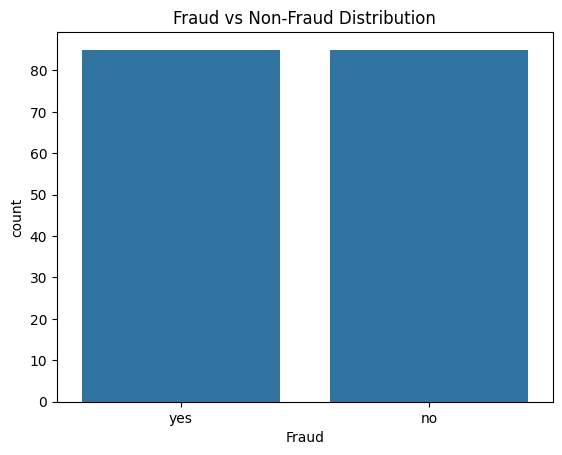

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Fraud", data=df)
plt.title("Fraud vs Non-Fraud Distribution")
plt.show()


In [7]:
X = df["Fillings"]
y = df["Fraud"]


In [8]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)  # yes → 1, no → 0


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [10]:
print("Training set size:", len(X_train))
print("Test set size:", len(X_test))
print("First training example:", X_train.iloc[0])
print("First training label:", y_train[0])


Training set size: 136
Test set size: 34
First training example: item 14 principal accounting fees services omitted additional disclosure items regulation ab item 1112b regulation ab significant obligor financial information mortgaged property securing park city center loan constitutes significant obligor within meaning 1101k2 regulation ab recent unaudited net operating income significant obligor 2012 fiscal year 2128112500 item 1114b2 regulation ab significant enhancement provider financial information entity group affiliated entities provides enhancement support certificates described item 1114a regulation ab item 1115b regulation ab certain derivatives instruments financial information entity group affiliated entities provides derivative instruments certificates described item 1115 regulation ab item 1117 regulation ab legal proceedings registrant knows pending legal proceeding legal proceeding contemplated governmental authorities sponsors depositor trustee issuing entity servicer

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text into numeric features
vectorizer = TfidfVectorizer(max_features=5000)  # limit to top 5000 words
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Shape of training data:", X_train_tfidf.shape)
print("Shape of test data:", X_test_tfidf.shape)


Shape of training data: (136, 5000)
Shape of test data: (34, 5000)


              precision    recall  f1-score   support

           0       0.87      0.72      0.79        18
           1       0.74      0.88      0.80        16

    accuracy                           0.79        34
   macro avg       0.80      0.80      0.79        34
weighted avg       0.81      0.79      0.79        34



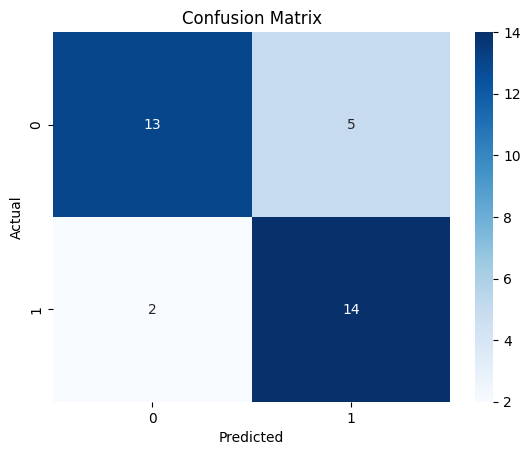

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Train the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_tfidf, y_train)

# Predict on test set
y_pred = model.predict(X_test_tfidf)

# Evaluation report
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Random Forest Results:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        18
           1       0.94      0.94      0.94        16

    accuracy                           0.94        34
   macro avg       0.94      0.94      0.94        34
weighted avg       0.94      0.94      0.94        34



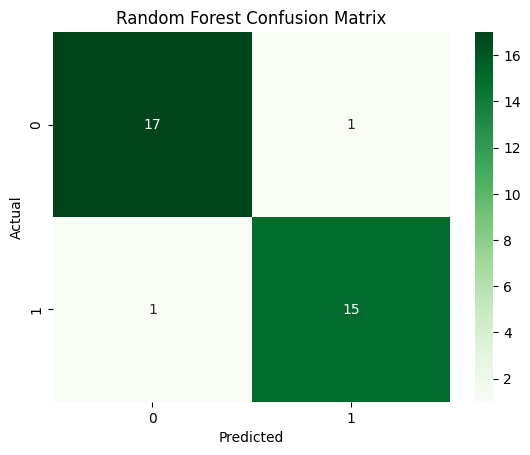

In [13]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_tfidf, y_train)

# Predict
y_pred_rf = rf_model.predict(X_test_tfidf)

# Evaluation
print("Random Forest Results:")
print(classification_report(y_test, y_pred_rf))

cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Greens")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [14]:
import numpy as np

# Get feature importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[-20:]  # top 20 features

# Map back to words
top_features = [vectorizer.get_feature_names_out()[i] for i in indices]

print("Top predictive words:", top_features)


Top predictive words: ['allowed', '232', 'manner', 'repurchase', 'headcount', '7aitem', '9item', 'initiatives', 'decline', '06', 'foreign', 'deductions', 'comparing', '114', 'disposal', 'currency', '8item', 'higher', '15item', 'denominated']


In [15]:
!pip install xgboost


   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 6.9 MB/s eta 0:00:07
   - -------------------------------------- 1.3/48.9 MB 5.2 MB/s eta 0:00:10
   - -------------------------------------- 2.4/48.9 MB 4.4 MB/s eta 0:00:11
   -- ------------------------------------- 3.1/48.9 MB 4.3 MB/s eta 0:00:11
   --- ------------------------------------ 3.9/48.9 MB 4.1 MB/s eta 0:00:11
   --- ------------------------------------ 4.7/48.9 MB 4.1 MB/s eta 0:00:11
   ---- ----------------------------------- 5.5/48.9 MB 4.0 MB/s eta 0:00:11
   ----- ---------------------------------- 6.3/48.9 MB 4.0 MB/s eta 0:00:11
   ----- ---------------------------------- 7.1/48.9 MB 4.0 MB/s eta 0:00:11
   ------ --------------------------------- 7.9/48.9 MB 4.0 MB/s eta 0:00:11
   ------- -------------------------------- 8.9/48.9 MB 4.0 MB/s eta 0:00:11
   ------- -------------------------------- 9.7/48.9 MB 4.0 MB/s eta 0:00:10
   ---


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Dell\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


C:\Users\Dell\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\xgboost\training.py:200: UserWarning: [23:43:12] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Results:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       1.00      1.00      1.00        16

    accuracy                           1.00        34
   macro avg       1.00      1.00      1.00        34
weighted avg       1.00      1.00      1.00        34



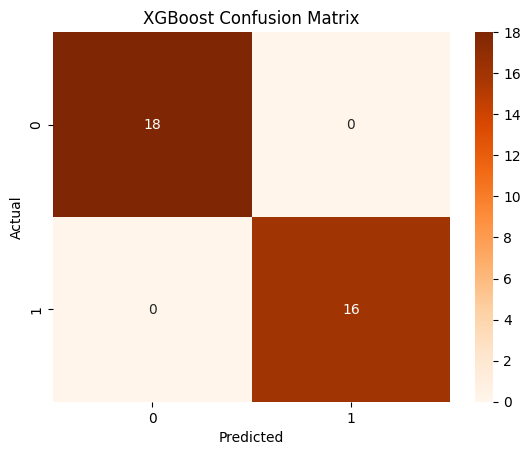

In [16]:
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Train XGBoost
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric="logloss", random_state=42)
xgb_model.fit(X_train_tfidf, y_train)

# Predict
y_pred_xgb = xgb_model.predict(X_test_tfidf)

# Evaluation
print("XGBoost Results:")
print(classification_report(y_test, y_pred_xgb))

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm_xgb, annot=True, fmt="d", cmap="Oranges")
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [17]:
import numpy as np

# Get feature importances from XGBoost
importances = xgb_model.feature_importances_

# Sort and pick top 20 features
indices = np.argsort(importances)[-20:]
top_features = [vectorizer.get_feature_names_out()[i] for i in indices]
top_importances = importances[indices]

# Display results
for word, score in zip(top_features, top_importances):
    print(f"{word}: {score:.4f}")


writeoffs: 0.0000
written: 0.0000
wrote: 0.0000
xbrl: 0.0000
xray: 0.0000
year: 0.0000
yearend: 0.0000
yearoveryear: 0.0000
years: 0.0000
yellow: 0.0000
yen: 0.0000
zealand: 0.0000
075: 0.0000
07: 0.0000
write: 0.0000
1015: 0.0000
yield: 0.0000
yields: 0.0000
york: 0.0000
8item: 1.0000


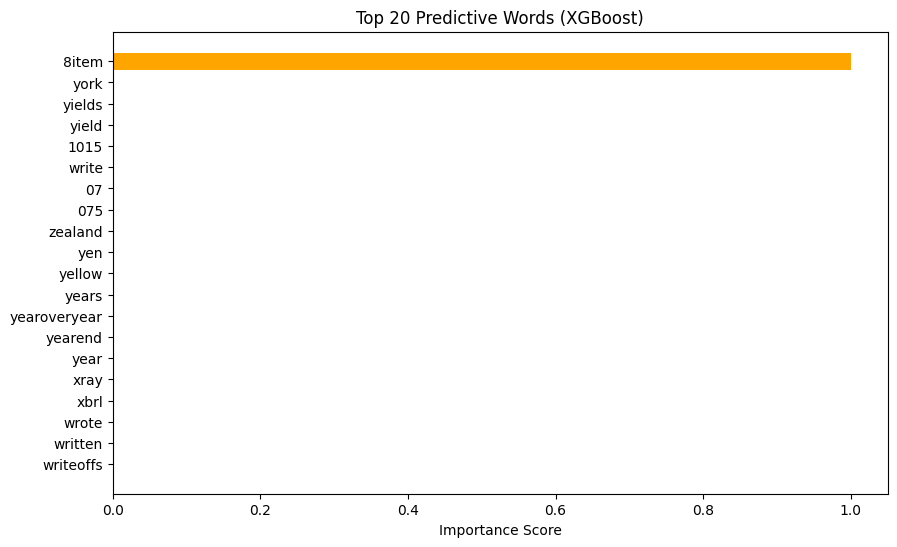

In [18]:
plt.figure(figsize=(10,6))
plt.barh(top_features, top_importances, color="orange")
plt.title("Top 20 Predictive Words (XGBoost)")
plt.xlabel("Importance Score")
plt.show()


In [19]:
import numpy as np

coef = model.coef_[0]
feature_names = vectorizer.get_feature_names_out()
top_positive_indices = np.argsort(coef)[-20:]
top_negative_indices = np.argsort(coef)[:20]

print("Top fraud-indicative words:", feature_names[top_positive_indices])
print("Top non-fraud-indicative words:", feature_names[top_negative_indices])



Top fraud-indicative words: ['2016' 'earnings' 'alcoa' 'impairment' 'assets' 'credit' '2018' 'segment'
 'value' 'december' 'plan' 'bellsouth' 'us' 'related' 'currency'
 'primarily' 'consolidated' 'tax' 'foreign' 'million']
Top non-fraud-indicative words: ['servicing' 'mortgage' 'servicer' 'bank' 'company' 'abbott' 'dominion'
 'item' 'securities' 'sprint' 'ihs' 'loan' 'warrants' 'shares' 'common'
 'loans' 'ab' 'compliance' 'trust' '30']
